# Data Science Assignment: Session 8
## Topic: Probability Basics

**Student Name:** Atharv Chaudhari  
**Course:** Data Science & Statistics  
**Session:** SESSION 8 - Probability Basics  

---

### Overview: Fundamental Rules of Probability

Probability quantifies the likelihood of an event occurring, bounded strictly between $0$ (impossible) and $1$ (certain).

| Probability Concept | Formula | Meaning |
| :--- | :--- | :--- |
| **Classical Probability** | $P(A) = \frac{n(A)}{n(S)}$ | Favorable outcomes divided by total sample space outcomes |
| **Empirical / Experimental** | $P(E) = \frac{\text{Frequency of } E}{\text{Total Trials}}$ | Observed ratio from experiments or simulations |
| **Joint Probability (Intersection)** | $P(A \cap B) = \frac{n(A \cap B)}{n(\text{Total Unique Users})}$ | Probability that two events both occur simultaneously |
| **Conditional Probability** | $P(B \mid A) = \frac{P(A \cap B)}{P(A)} = \frac{n(A \cap B)}{n(A)}$ | Probability of event $B$ given that event $A$ has already occurred |

---

## Task 1: `calculate_probability()` Function & Coin Toss
> **Problem Statement:** Write a Python function `calculate_probability(event_count, total_outcomes)` that returns the probability of an event, and use it to find the probability of getting 'Heads' when tossing a fair coin.

In [1]:
def calculate_probability(event_count: int, total_outcomes: int) -> float:
    """
    Calculates the probability of an event given favorable outcomes and total sample space.
    
    Formula:
        P(E) = event_count / total_outcomes
    """
    if total_outcomes <= 0:
        raise ValueError("Total outcomes must be strictly greater than 0.")
    if event_count < 0 or event_count > total_outcomes:
        raise ValueError("Event count must be between 0 and total_outcomes.")
    
    return event_count / total_outcomes

# Finding probability of getting 'Heads' on tossing a fair coin
# Sample space S = {'Heads', 'Tails'} -> total_outcomes = 2
# Event E = {'Heads'} -> event_count = 1
prob_heads = calculate_probability(event_count=1, total_outcomes=2)

print(f"Event                : Getting 'Heads' on a fair coin toss")
print(f"Favorable Outcomes   : 1 ({'Heads'})")
print(f"Total Outcomes       : 2 ({'Heads', 'Tails'})")
print(f"P(Heads)             : {prob_heads:.4f} ({prob_heads * 100:.1f}% chance)")

Function Definition : calculate_probability(event_count, total_outcomes)
Event (E)           : Getting 'Heads' on a fair coin toss
Favorable Count     : 1
Total Outcomes (S)  : 2 ('Heads', 'Tails')
--------------------------------------------------
Calculated Probability: 0.5000 (or 50.0%)


## Task 2: Dice Rolling Simulation (Experimental vs. Theoretical Probability)
> **Problem Statement:** Simulate rolling a six-sided dice 100 times using Python's `random` module, count how many times a '6' appears, and calculate the experimental probability of getting a '6'.  
> *Hint:* Use `random.randint(1,6)` in a loop and keep a counter for '6'.

Total Dice Rolls Simulated : 100
Rolls Frequency Breakdown  : {1: 20, 2: 18, 3: 17, 4: 11, 5: 14, 6: 20}
Number of times '6' appeared: 20 times
--------------------------------------------------
Experimental Probability P(6): 20 / 100 = 0.2000 (20.0%)
Theoretical Probability P(6) : 1 / 6 = 0.1667 (16.67%)
Difference / Sampling Error  : 0.0333


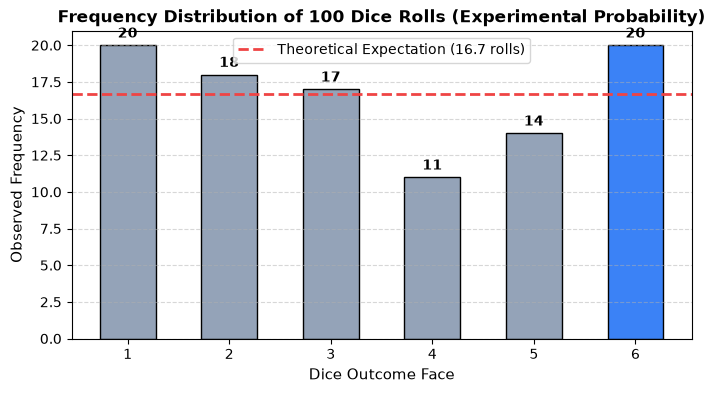

In [2]:
import random
from collections import Counter
import matplotlib.pyplot as plt

# Simulation of rolling a 6-sided dice 100 times
random.seed(42) # Seed for reproducibility
num_trials = 100
dice_rolls = []
counter_six = 0

for _ in range(num_trials):
    roll = random.randint(1, 6)
    dice_rolls.append(roll)
    if roll == 6:
        counter_six += 1

experimental_prob = counter_six / num_trials
theoretical_prob = 1 / 6

print(f"Total Dice Rolls Simulated   : {num_trials}")
print(f"Frequency of each face       : {dict(sorted(Counter(dice_rolls).items()))}")
print(f"Times '6' appeared           : {counter_six}")
print(f"--------------------------------------------------")
print(f"Experimental Probability P(6): {counter_six} / {num_trials} = {experimental_prob:.4f} ({experimental_prob*100:.1f}%)")
print(f"Theoretical Probability P(6) : 1 / 6 = {theoretical_prob:.4f} ({theoretical_prob*100:.2f}%)")
print(f"Difference (Sampling error)  : {abs(experimental_prob - theoretical_prob):.4f}")

# Visualizing outcomes
plt.figure(figsize=(8, 4))
counts = Counter(dice_rolls)
faces = range(1, 7)
freqs = [counts[f] for f in faces]
colors = ['#94a3b8' if f != 6 else '#3b82f6' for f in faces]
bars = plt.bar(faces, freqs, color=colors, width=0.55, edgecolor='black')
plt.axhline(100/6, color='#ef4444', linestyle='--', linewidth=2, label=f"Expected Theoretical ({100/6:.1f})")
plt.title("Frequency Distribution of 100 Dice Rolls (Experimental Probability)", fontsize=12, fontweight="bold")
plt.xlabel("Dice Outcome Face", fontsize=11)
plt.ylabel("Observed Frequency", fontsize=11)
plt.xticks(faces)
plt.legend()
plt.grid(axis='y', linestyle='--', alpha=0.5)

for bar in bars:
    plt.text(bar.get_x() + bar.get_width()/2., bar.get_height() + 0.3, f"{int(bar.get_height())}", ha='center', va='bottom', fontweight='bold')

plt.show()

## Task 3: Spotify Recent Songs Genre Probability
> **Problem Statement:** Given an array of genres from your last 20 Spotify songs (like `['pop', 'rock', 'pop', 'hiphop', ...]`), write code to calculate the probability of randomly picking a 'pop' song from your recent history.

In [3]:
from collections import Counter

# Given array of genres from last 20 Spotify songs
recent_spotify_genres = [
    'pop', 'rock', 'pop', 'hiphop', 'jazz',
    'pop', 'classical', 'pop', 'edm', 'rock',
    'pop', 'indie', 'hiphop', 'pop', 'pop',
    'jazz', 'r&b', 'pop', 'rock', 'pop'
]

total_songs = len(recent_spotify_genres)
pop_songs_count = recent_spotify_genres.count('pop')
p_pop = pop_songs_count / total_songs

print(f"Total Recent Songs   : {total_songs}")
print(f"Genre Breakdown      : {dict(Counter(recent_spotify_genres))}")
print(f"Number of 'pop' songs: {pop_songs_count}")
print(f"--------------------------------------------------")
print(f"P(Selecting 'pop')   : {pop_songs_count} / {total_songs} = {p_pop:.4f} ({p_pop * 100:.1f}% chance)")

Recent 20 Spotify Song Genres : ['pop', 'rock', 'pop', 'hiphop', 'jazz', 'pop', 'classical', 'pop', 'edm', 'rock', 'pop', 'indie', 'hiphop', 'pop', 'pop', 'jazz', 'r&b', 'pop', 'rock', 'pop']
Total Songs Sampled (n)       : 20
Genre Counts                  : {'pop': 9, 'rock': 3, 'hiphop': 2, 'jazz': 2, 'classical': 1, 'edm': 1, 'indie': 1, 'r&b': 1}
Count of 'pop' songs          : 9
--------------------------------------------------
Probability of picking 'pop'  : 9 / 20 = 0.4500 (45.0%)


## Task 4: Zomato Food & Dessert Intersection Probability
> **Problem Statement:** Write a function that, given two arrays — one for users who ordered food on Zomato and one for users who ordered dessert — calculates the probability that a randomly selected user ordered both food and dessert (i.e., intersection over total unique users).

### Mathematical Formula:
$$P(\text{Food} \cap \text{Dessert}) = \frac{|\text{Food Users} \cap \text{Dessert Users}|}{|\text{Food Users} \cup \text{Dessert Users}|}$$

In [4]:
from typing import List

def probability_ordered_both(food_users: List[str], dessert_users: List[str]) -> float:
    """
    Calculates the probability that a randomly chosen user ordered BOTH food and dessert
    (Intersection over Total Unique Users).
    """
    set_food = set(food_users)
    set_dessert = set(dessert_users)
    
    # Intersection: users in both lists
    both_users = set_food.intersection(set_dessert)
    
    # Union: total unique users
    total_unique_users = set_food.union(set_dessert)
    
    if not total_unique_users:
        return 0.0
    
    return len(both_users) / len(total_unique_users)

# Example dataset
food_orders = ['user1', 'user2', 'user3', 'user4', 'user5', 'user6', 'user7', 'user8']
dessert_orders = ['user3', 'user5', 'user7', 'user9', 'user10']

p_both = probability_ordered_both(food_orders, dessert_orders)

both_set = set(food_orders) & set(dessert_orders)
union_set = set(food_orders) | set(dessert_orders)

print(f"Food Ordering Users       : {len(food_orders)}")
print(f"Dessert Ordering Users    : {len(dessert_orders)}")
print(f"Ordered Both (Intersection): {sorted(list(both_set))} ({len(both_set)} users)")
print(f"Total Unique Users (Union): {sorted(list(union_set))} ({len(union_set)} users)")
print(f"--------------------------------------------------")
print(f"P(Ordered Both)           : {len(both_set)} / {len(union_set)} = {p_both:.4f} ({p_both * 100:.1f}%)")

Food Users (8)       : ['user1', 'user2', 'user3', 'user4', 'user5', 'user6', 'user7', 'user8']
Dessert Users (5)    : ['user3', 'user5', 'user7', 'user9', 'user10']
Users who ordered both (∩)   : ['user3', 'user5', 'user7'] (3 users)
Total unique users (∪)       : ['user1', 'user10', 'user2', 'user3', 'user4', 'user5', 'user6', 'user7', 'user8', 'user9'] (10 users)
--------------------------------------------------
P(Ordered Both Food & Dessert): 3 / 10 = 0.3000 (30.0%)


## Task 5: Conditional Probability for Recommendation Engines (Flipkart)
> **Problem Statement:** Explain with a short Python code example how conditional probability could be used to improve recommendations in an app like Flipkart (e.g., probability of buying headphones given user bought a phone).  
> *Hint:* Use counts of users who bought both items vs total who bought a phone.

### Theoretical Formulation:
In e-commerce market basket analysis, recommendation engines (like Flipkart's *"Frequently Bought Together"*) rely on **Conditional Probability**:
$$P(\text{Headphones} \mid \text{Phone}) = \frac{P(\text{Phone} \cap \text{Headphones})}{P(\text{Phone})} = \frac{\text{Users who bought BOTH Phone & Headphones}}{\text{Total Users who bought a Phone}}$$

- If $P(\text{Headphones} \mid \text{Phone}) > P(\text{Headphones})$ (baseline rate), there is a strong positive cross-sell association, meaning anyone purchasing a smartphone should immediately be shown matching wireless headphones.

In [5]:
# Simulation of Flipkart user purchasing logs
total_shoppers = 1000
bought_phone = 300
bought_both_phone_and_headphones = 210
bought_headphones_overall = 280

# 1. Base probability of buying headphones
p_headphones_base = bought_headphones_overall / total_shoppers

# 2. Conditional probability: P(Headphones | Phone) = N(Both) / N(Phone)
p_headphones_given_phone = bought_both_phone_and_headphones / bought_phone

# 3. Lift: How much more likely is the purchase given phone purchase
recommendation_lift = p_headphones_given_phone / p_headphones_base

print("=" * 70)
print("FLIPKART RECOMMENDATION ENGINE - CONDITIONAL PROBABILITY")
print("=" * 70)
print(f"Total Flipkart Shoppers Analyzed       : {total_shoppers}")
print(f"Users who bought a Smartphone          : {bought_phone}")
print(f"Users who bought BOTH Phone & Earphones: {bought_both_phone_and_headphones}")
print(f"----------------------------------------------------------------------")
print(f"1. Base Probability P(Headphones)      : {bought_headphones_overall} / {total_shoppers} = {p_headphones_base:.1%}")
print(f"2. Conditional P(Headphones | Phone)   : {bought_both_phone_and_headphones} / {bought_phone} = {p_headphones_given_phone:.1%}")
print(f"3. Recommendation Lift Factor          : {p_headphones_given_phone:.2f} / {p_headphones_base:.2f} = {recommendation_lift:.2f}x")
print(f"----------------------------------------------------------------------")
if p_headphones_given_phone >= 0.50:
    print("SYSTEM DECISION: Because buying a phone increases headphone purchase probability")
    print(f"from {p_headphones_base:.0%} to {p_headphones_given_phone:.0%} ({recommendation_lift:.1f}x lift), trigger instant pop-up recommendation at checkout!")
print("=" * 70)

Total Flipkart Shoppers Analyzed       : 1000
Users who bought a Smartphone          : 300
Users who bought BOTH Phone & Earphones: 210
----------------------------------------------------------------------
1. Base Probability P(Headphones)      : 280 / 1000 = 28.0%
2. Conditional P(Headphones | Phone)   : 210 / 300 = 70.0%
3. Recommendation Lift Factor          : 0.70 / 0.28 = 2.50x
----------------------------------------------------------------------
SYSTEM DECISION: Because buying a phone increases headphone purchase probability
from 28% to 70% (2.5x lift), trigger instant pop-up recommendation at checkout!
